# 16 · Complete ML pipeline

[Guide](../README.md) | [Previous](15_Final_Frozen_Solution.ipynb)

Run one selected model, check its predictions, and export a submission. Finish with an optional example of how a different decision rule changes predictions.

## Choices carried forward

| Phase | Choice |
|---|---|
| Missing values | Keep rows; fill numbers with the median and categories with the mode |
| Scaling and encoding | Robust scaling and one-hot encoding |
| Features | The 20 candidates explained below |
| Selection | Drop suspected decoys, then L1 selection |
| Outliers | Add an indicator; do not delete rows just because they look unusual |
| Balancing and PCA | No resampling; no PCA |
| Model | One CatBoost model: 200 trees, depth 6, learning rate 0.1 |
| Normal decision cutoff | 0.47, selected using training-only predictions |

**Why keep incomplete rows?** A follow-up three-fold training comparison gave F1 **0.9473**, versus **0.9461** for dropping them, at cutoff 0.50. The gain is small, but keeping rows also avoids discarding usable information.

**Why 0.47?** It gave the highest F1 on this candidate's training out-of-fold predictions: each row was predicted by a model fitted without that row. This selection score is not an independent final evaluation.

The earlier lessons retain their original stage-by-stage comparisons. These two follow-up changes are specific to this final pipeline.

## Data: training, validation, competition test
`train.csv` contains known answers; `test.csv` does not.
Split `train.csv`: 16,000 rows for learning and comparisons; 4,000 validation rows for the final check.
Comparisons below stay inside the training part. `random_state` repeats the split;
`stratify` keeps similar goal/miss proportions. `X` means inputs; `y` means answers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.precision", 3)

In [2]:
# Change this one folder on Kaggle or Colab (see the guide).
DATA_DIR = "../data"
train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")
print("Train:", train.shape, "Test:", test.shape)

Train: (20000, 20) Test: (6000, 19)


In [3]:
# Split train.csv: 80% for training, 20% for a separate validation check.
training_data, validation_data = train_test_split(
    train, test_size=0.20, stratify=train["is_scored"], random_state=2026
)
training_data = training_data.reset_index(drop=True)

In [4]:
# IDs identify rows; they do not describe how a penalty was taken.
id_columns = ["id", "kicker_id", "keeper_id", "match_id"]
X = training_data.drop(columns=id_columns + ["is_scored"])
y = training_data["is_scored"]

In [5]:
from sklearn.base import clone
from sklearn.compose import make_column_selector
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.feature_selection import SelectFromModel
from imblearn.pipeline import Pipeline
from catboost import CatBoostClassifier

**Keep incomplete rows:** a blank value does not make the whole penalty useless. The pipeline learns median/mode filling values from its training rows only.

In [6]:
# The cutoff turns a probability into a goal/miss prediction.
# This value was selected inside the 16,000-row training part, not on test answers.
TRAINING_CUTOFF = 0.47

**Suspected decoys:** test removing jersey color and referee strictness, not every weak-looking input. The same columns are removed at prediction time.

In [7]:
def drop_suspected_decoys(data):
    return data.drop(columns=["jersey_color", "referee_strictness"], errors="ignore")

**Form and technique features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [8]:
def add_relative_features(data):
    data = data.copy()
    data["skill_gap"] = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["foot_advantage"] = data["strong_foot_usage"] - data["weak_foot_usage"]
    data["form_ratio"] = (data["player_last5_scored_percent"] + 1) / (data["goalkeeper_last5_saved_percent"] + 1)
    data["form_interaction"] = data["player_last5_scored_percent"] * data["goalkeeper_last5_saved_percent"] / 100
    data["player_form_squared"] = (data["player_last5_scored_percent"] / 100) ** 2
    data["keeper_form_squared"] = (data["goalkeeper_last5_saved_percent"] / 100) ** 2
    return data

**Match context features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [9]:
def add_pressure_features(data):
    data = data.copy()
    data["late_close_game"] = ((data["minute_taken"] >= 75) & (data["current_score_diff"].abs() <= 1)).astype(int)
    gap = data["player_last5_scored_percent"] - data["goalkeeper_last5_saved_percent"]
    data["skill_under_pressure"] = gap * data["late_close_game"]
    data["after_90_minutes"] = (data["minute_taken"] > 90).astype(int)
    data["trailing"] = (data["current_score_diff"] < 0).astype(int)
    data["tied_game"] = (data["current_score_diff"] == 0).astype(int)
    data["minute_score_interaction"] = data["minute_taken"] * data["current_score_diff"]
    data["crowd_support"] = (data["home_or_away"] == data["crowd_behind_goal"]).astype(int)
    data["late_final"] = ((data["minute_taken"] >= 75) & (data["match_type"] == "Final")).astype(int)
    return data

**Environment features:** keep the original inputs and add this group's formulas. `copy()` leaves the original table unchanged; `FunctionTransformer` puts this table-editing function into the pipeline.

In [10]:
def add_environment_features(data):
    data = data.copy()
    data["poor_pitch"] = (data["pitch_condition"] == "Poor").astype(int)
    data["poor_pitch_late"] = data["poor_pitch"] * (data["minute_taken"] >= 75)
    data["humidity_weak_foot"] = data["weather_humidity"] / 100 * data["weak_foot_usage"]
    data["humidity_squared"] = (data["weather_humidity"] / 100) ** 2
    data["temperature_squared"] = data["temperature"] ** 2
    data["log_capacity"] = np.log1p(data["stadium_capacity"])
    return data

In [11]:
def add_features(data):
    data = add_relative_features(data)
    data = add_pressure_features(data)
    return add_environment_features(data)

In [12]:
def suspicious_rows(data):
    # Screening rules, not proof: unusual time, cold weather, or very large venue.
    return ((data["minute_taken"] > 120) |
            (data["temperature"] < 0) |
            (data["stadium_capacity"] > 110000))

In [13]:
def add_outlier_flag(data):
    data = data.copy()
    data["unusual_kick"] = suspicious_rows(data).astype(int)
    return data

## Prepare each training split separately
Fill numbers with a training mean or median; fill categories with the most common value (**mode**).
Scaling puts numbers on similar scales. Encoding turns category names into numbers (Lesson 04).
No filling values, rankings, or sampling decisions are learned from validation rows.

In [14]:
numbers = Pipeline([("fill", SimpleImputer(strategy='median')), ("scale", RobustScaler())])
categories = Pipeline([
    ("fill", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("numbers", numbers, make_column_selector(dtype_include="number")),
    ("categories", categories, make_column_selector(dtype_exclude="number")),
])

**Pipeline:** run the steps in order. Filling, scaling, encoding and feature selection learn from training rows only. Validation and test rows are never removed.

In [15]:
pipeline = Pipeline([
    ("outlier_values", FunctionTransformer(add_outlier_flag)),
    ("features", FunctionTransformer(add_features)),
    ("decoys", FunctionTransformer(drop_suspected_decoys)),
    ("prepare", preprocess),
    ("selection", SelectFromModel(LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000, random_state=42))),
    ("model", CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1, loss_function='Logloss', random_seed=42, thread_count=2, verbose=False, allow_writing_files=False)),
])

In [16]:
selected_model = clone(pipeline)

## Earlier model comparison

| Model in Lesson 10 | Cross-validation F1 |
|---|---:|
| CatBoost | 0.9440 |
| Gradient boosting | 0.9420 |
| XGBoost | 0.9400 |
| Random forest | 0.9270 |
| Extra trees | 0.9260 |
| Logistic regression | 0.8990 |
| Decision tree | 0.8780 |
| RBF support vector machine | 0.8720 |

These are Lesson 10's measured scores, not a new search in this notebook.

## Check the fixed recipe on validation rows

F1 balances precision (how often a predicted goal is correct) and recall (how many real goals we find).
Use the cutoff selected on training predictions; do not choose it from this validation score.

This validation split has been inspected before. Treat its score as a learning example, not a fresh independent benchmark. Performance on a different dataset may change.

,validation F1,validation accuracy,validation ROC-AUC
0,0.941,0.947,0.991


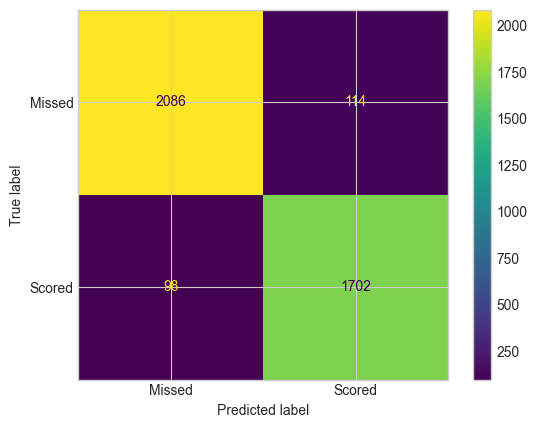

In [17]:
from sklearn.metrics import f1_score, accuracy_score, roc_auc_score, ConfusionMatrixDisplay
X_valid = validation_data.drop(columns=id_columns + ["is_scored"])
y_valid = validation_data["is_scored"]
selected_model.fit(X, y)
validation_probability = selected_model.predict_proba(X_valid)[:, 1]
validation_prediction = (validation_probability >= TRAINING_CUTOFF).astype(int)
validation_results = pd.DataFrame([[
    f1_score(y_valid, validation_prediction), accuracy_score(y_valid, validation_prediction),
    roc_auc_score(y_valid, validation_probability),
]], columns=["validation F1", "validation accuracy", "validation ROC-AUC"])
display(validation_results.round(4))
ConfusionMatrixDisplay.from_predictions(y_valid, validation_prediction, display_labels=["Missed", "Scored"])
plt.show()

## Fit the same model using the full training file

Keep and impute incomplete rows. Every competition-test row gets a probability and a prediction.

In [18]:
final_model = clone(selected_model)
X_all = train.drop(columns=id_columns + ["is_scored"])
y_all = train["is_scored"]
X_test = test.drop(columns=id_columns)
final_model.fit(X_all, y_all)
test_probability = final_model.predict_proba(X_test)[:, 1]
prediction = (test_probability >= TRAINING_CUTOFF).astype(int)
submission = pd.DataFrame({"id": test["id"], "is_scored": prediction})
assert len(submission) == len(test)
assert submission["id"].is_unique and submission["is_scored"].isin([0, 1]).all()
display(submission.head())

,id,is_scored
0,20000,1
1,20001,0
2,20002,1
3,20003,0
4,20004,1


In [19]:
from pathlib import Path
OUTPUT_DIR = "../results/pipeline_update"
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
submission.to_csv(f"{OUTPUT_DIR}/learning_pipeline_training_cutoff.csv", index=False)
print("Saved the normal training-selected predictions.")

Saved the normal training-selected predictions.


In [20]:
validation_results.to_csv(f"{OUTPUT_DIR}/validation_results.csv", index=False)

## Optional: what if we expect half the penalties to score?

**Assumption, not a measured fact:** about 50% of the test penalties are goals. We cannot determine the true goal rate from an unlabeled test file.

Rank the predicted probabilities and label the upper half as goals. `quantile(0.50)` finds the middle probability, which becomes the new cutoff.

This example changes only the decision rule. It does not rebalance training data or make the probabilities more accurate. The 50% assumption was not selected by training validation. Use a rule like this only when a credible, independent source supports the expected rate. Otherwise, keep the training-selected cutoff. A wrong assumption can lower F1.

In [21]:
EXPECTED_TEST_GOAL_RATE = 0.50
competition_cutoff = np.quantile(test_probability, 1 - EXPECTED_TEST_GOAL_RATE)
competition_prediction = (test_probability >= competition_cutoff).astype(int)
competition_submission = pd.DataFrame({"id": test["id"], "is_scored": competition_prediction})
competition_submission.to_csv(f"{OUTPUT_DIR}/learning_pipeline_expected50_experiment.csv", index=False)
print("Experiment cutoff:", round(competition_cutoff, 4))
print("Predicted goals:", competition_prediction.sum(), "out of", len(test))

Experiment cutoff: 0.148
Predicted goals: 3000 out of 6000


**What changed for one penalty?** A probability between the two cutoffs changes from miss to goal. We have changed the decision rule, not retrained the model or proved that the new label is correct.

In [22]:
prediction_examples = pd.DataFrame({
    "id": test["id"], "goal_probability": test_probability,
    "normal_prediction": prediction, "experiment_prediction": competition_prediction,
})
display(prediction_examples.loc[prediction != competition_prediction].head().round(3))
prediction_examples.to_csv(f"{OUTPUT_DIR}/learning_pipeline_probabilities.csv", index=False)

,id,goal_probability,normal_prediction,experiment_prediction
7,20007,0.165,0,1
19,20019,0.301,0,1
35,20035,0.422,0,1
60,20060,0.363,0,1
76,20076,0.153,0,1


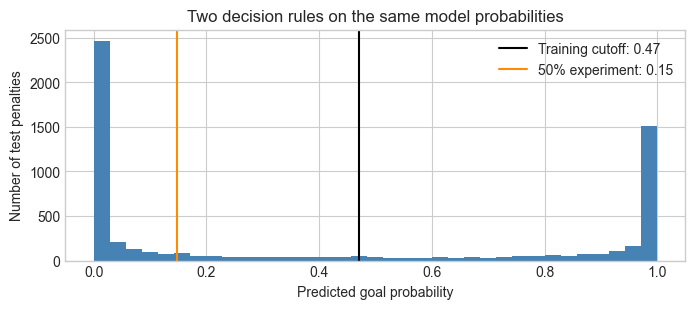

In [23]:
plt.figure(figsize=(8, 3))
plt.hist(test_probability, bins=35, color="steelblue")
plt.axvline(TRAINING_CUTOFF, color="black", label=f"Training cutoff: {TRAINING_CUTOFF:.2f}")
plt.axvline(competition_cutoff, color="darkorange", label=f"50% experiment: {competition_cutoff:.2f}")
plt.xlabel("Predicted goal probability")
plt.ylabel("Number of test penalties")
plt.title("Two decision rules on the same model probabilities")
plt.legend()
plt.show()

## Export summary

The normal file uses the training-selected cutoff. The optional file uses the assumed 50% goal rate. Keep their names separate: the assumption-based experiment is not the default ML pipeline and has no independently validated test score in this notebook.

In [24]:
export_summary = pd.DataFrame({
    "file": ["learning_pipeline_training_cutoff.csv", "learning_pipeline_expected50_experiment.csv"],
    "cutoff": [TRAINING_CUTOFF, competition_cutoff],
    "predicted_goals": [prediction.sum(), competition_prediction.sum()],
    "test_rows": [len(test), len(test)],
})
display(export_summary.round(4))
export_summary.to_csv(f"{OUTPUT_DIR}/pipeline_export_summary.csv", index=False)

,file,cutoff,predicted_goals,test_rows
0,learning_pipeline_training_cutoff.csv,0.470,2478,6000
1,learning_pipeline_expected50_experiment.csv,0.148,3000,6000
